# **Machine Learning No Supervisado**
Juan Manuel Pastor Salamanca

## **Preparación**

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_style("whitegrid")
fmt_pesos = FuncFormatter(lambda v, _: f"${v/1e6:.1f}M")

In [49]:
from google.colab import files
subido = files.upload()
nombre_archivo = list(subido.keys())[0]

df_base = pd.read_excel(nombre_archivo)
print("Archivo:", nombre_archivo)
print("Filas y columnas:", df_base.shape)
print("Columnas:", list(df_base.columns))
df_base.describe().round(2)

Saving DATASET_INmuebles.xlsx to DATASET_INmuebles.xlsx
Archivo: DATASET_INmuebles.xlsx
Filas y columnas: (1000, 9)
Columnas: ['Inmueble', 'Area', 'Habitaciones', 'Estrato', 'Precio Arriendo', 'Banos', 'Antiguedad', 'Localidad', 'Tipo Inmueble']


,Area,Habitaciones,Estrato,Precio Arriendo,Banos,Antiguedad
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,96.73,2.66,3.96,3633286.68,1.48,8.46
std,54.10,1.28,1.43,2438534.26,0.50,2.35
min,30.00,1.00,2.00,702480.00,1.00,5.00
25%,55.00,2.00,3.00,1644060.25,1.00,6.00
50%,80.50,2.00,4.00,2930804.50,1.00,8.50
75%,135.00,4.00,5.00,5394807.00,2.00,10.00
max,220.00,5.00,6.00,8988836.00,2.00,12.00


In [34]:
col_id      = "Inmueble"
col_precio  = "Precio Arriendo"
col_area    = "Area"
vars_num    = ["Precio Arriendo", "Area", "Habitaciones", "Banos",
               "Antiguedad", "Estrato"]
vars_cat    = ["Localidad", "Tipo Inmueble"]

In [35]:
# Funciones auxiliares (se usan en las Partes A y B)

def ordenar_por_precio(etiquetas, precios):
    # Se utiliza para organizar el resultado de k-means de la siguiente manera:
    # Clúster 0: Inmuebles económicos (menor área, estratos bajos o medios, precio de arriendo bajo, 1 o 2 habitaciones).
    # Clúster 1: Inmuebles intermedios (área media, 2 o 3 habitaciones, estrato medio, precio moderado).
    # Clúster 2: Inmuebles premium (mayor área, estrato alto, más habitaciones, precio elevado)

    medio = pd.Series(np.asarray(precios)).groupby(np.asarray(etiquetas)).mean().sort_values()
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(medio.index)}
    nuevas = np.array([mapa[e] for e in etiquetas])
    return nuevas, list(medio.index)

def alinear(ref, otro):
   # Esta función compara los grupos de referencia con los otros grupos, para poder compararlos correctamente
    tabla = pd.crosstab(np.asarray(ref), np.asarray(otro))
    filas, cols = linear_sum_assignment(-tabla.values)
    mapa = {tabla.columns[c]: tabla.index[f] for f, c in zip(filas, cols)}
    return np.array([mapa.get(x, x) for x in np.asarray(otro)])

# **Parte A: Agrupación con K-Means**


### Leer el Excel y preparar las variables para el clustering


In [36]:
df_A = df_base.copy()
ids_A = df_A[col_id]                       # el ID solo sirve para identificar registros

X_A = df_A[vars_num]                       # variables que SÍ calculan distancias

scaler_A = StandardScaler()                # se escalan las distancias
X_scaled_A = scaler_A.fit_transform(X_A)

print("Variables usadas en el modelo:", vars_num)
print("Forma de la matriz escalada:", X_scaled_A.shape)
df_A.head()

Variables usadas en el modelo: ['Precio Arriendo', 'Area', 'Habitaciones', 'Banos', 'Antiguedad', 'Estrato']
Forma de la matriz escalada: (1000, 6)


,Inmueble,Area,Habitaciones,Estrato,Precio Arriendo,Banos,Antiguedad,Localidad,Tipo Inmueble
0,I1,69,2,2,1413951,2,11,Suba,Apto
1,I2,39,1,2,1006165,2,10,Chapinero,Casa
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio
3,I4,62,3,4,3678698,1,12,Suba,Apto
4,I5,58,1,3,875729,1,12,Chapinero,Casa


### Función que ejecuta K-Means y produce todos los resultados


In [37]:
res_A = {}   # aquí se guardan los resultados de cada k

def ejecutar_kmeans(k):
    # --- Modelo (parámetros exigidos por la actividad) ---
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_scaled_A)

    # --- Renumerar grupos por precio medio (0 = más económico) ---
    nuevas, orden = ordenar_por_precio(modelo.labels_, df_A[col_precio])
    col_cl = f"cluster_k{k}"
    df_A[col_cl] = nuevas
    centros_esc = modelo.cluster_centers_[orden]                       # escala estandarizada
    centros_orig = pd.DataFrame(scaler_A.inverse_transform(centros_esc),
                                columns=vars_num).round(2)             # escala real
    centros_orig.index.name = "cluster"

    sil = silhouette_score(X_scaled_A, nuevas)
    tam = df_A[col_cl].value_counts().sort_index()

    # --- Resultados numéricos ---
    print("=" * 70)
    print(f"K-MEANS con k = {k}   |   Inercia = {modelo.inertia_:.2f}   |   Silueta = {sil:.3f}")
    print("=" * 70)
    print("\nTamaño de cada cluster:\n", tam.to_string())
    print("\nCentroides en escala estandarizada:\n", pd.DataFrame(centros_esc, columns=vars_num).round(2))
    print("\nCentroides en escala original:\n", centros_orig)
    resumen = df_A.groupby(col_cl)[vars_num].mean().round(2)
    resumen.insert(0, "n_inmuebles", tam)
    print("\nResumen promedio por cluster:\n", resumen)

    # --- Figura 1: dispersión con centroides + mapa de calor del perfil ---
    fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.1, 1]})
    for g in range(k):
        s = df_A[col_cl] == g
        ax[0].scatter(df_A.loc[s, col_area], df_A.loc[s, col_precio], alpha=0.7,
                      label=f"Cluster {g} (n={tam[g]})")
    ax[0].scatter(centros_orig[col_area], centros_orig[col_precio], marker="X", s=260,
                  c="black", edgecolor="white", linewidth=1.5, label="Centroides", zorder=5)
    ax[0].yaxis.set_major_formatter(fmt_pesos)
    ax[0].set_xlabel("Área del inmueble (m²)"); ax[0].set_ylabel("Precio de arriendo")
    ax[0].set_title(f"Segmentación de inmuebles (k={k})"); ax[0].legend()

    perfil = pd.DataFrame(centros_esc, columns=vars_num,
                          index=[f"Cluster {g} (n={tam[g]})" for g in range(k)])
    sns.heatmap(perfil, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
    ax[1].set_title("Perfil de cada cluster (centroides estandarizados)")
    plt.tight_layout(); plt.show()



### Ejecución con 2 - 3 - 4 clusters

K-MEANS con k = 2   |   Inercia = 3113.60   |   Silueta = 0.422

Tamaño de cada cluster:
 cluster_k2
0    618
1    382

Centroides en escala estandarizada:
    Precio Arriendo  Area  Habitaciones  Banos  Antiguedad  Estrato
0            -0.68 -0.66         -0.65  -0.02        0.03    -0.68
1             1.09  1.07          1.05   0.02       -0.05     1.10

Centroides en escala original:
          Precio Arriendo    Area  Habitaciones  Banos  Antiguedad  Estrato
cluster                                                                   
0             1984490.07   60.98          1.83   1.47        8.52     2.98
1             6300711.57  154.56          4.01   1.49        8.35     5.53

Resumen promedio por cluster:
             n_inmuebles  Precio Arriendo    Area  Habitaciones  Banos  \
cluster_k2                                                              
0                   618       1984490.07   60.98          1.83   1.47   
1                   382       6300711.57  154.56          

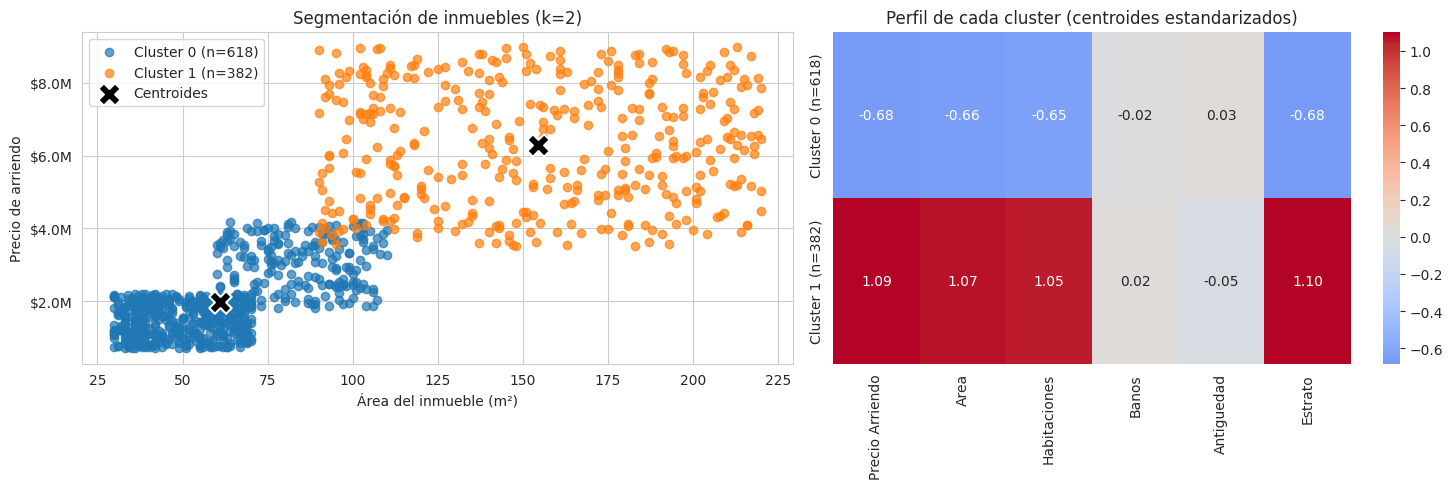

In [50]:
ejecutar_kmeans(2)

K-MEANS con k = 3   |   Inercia = 2496.26   |   Silueta = 0.345

Tamaño de cada cluster:
 cluster_k3
0    292
1    326
2    382

Centroides en escala estandarizada:
    Precio Arriendo  Area  Habitaciones  Banos  Antiguedad  Estrato
0            -0.68 -0.67         -0.65   1.04        0.01    -0.68
1            -0.67 -0.66         -0.65  -0.96        0.04    -0.68
2             1.09  1.07          1.05   0.02       -0.05     1.10

Centroides en escala original:
          Precio Arriendo    Area  Habitaciones  Banos  Antiguedad  Estrato
cluster                                                                   
0             1967061.15   60.68          1.83   2.00        8.48     2.98
1             2000101.25   61.25          1.83   1.00        8.56     2.99
2             6300711.57  154.56          4.01   1.49        8.35     5.53

Resumen promedio por cluster:
             n_inmuebles  Precio Arriendo    Area  Habitaciones  Banos  \
cluster_k3                                           

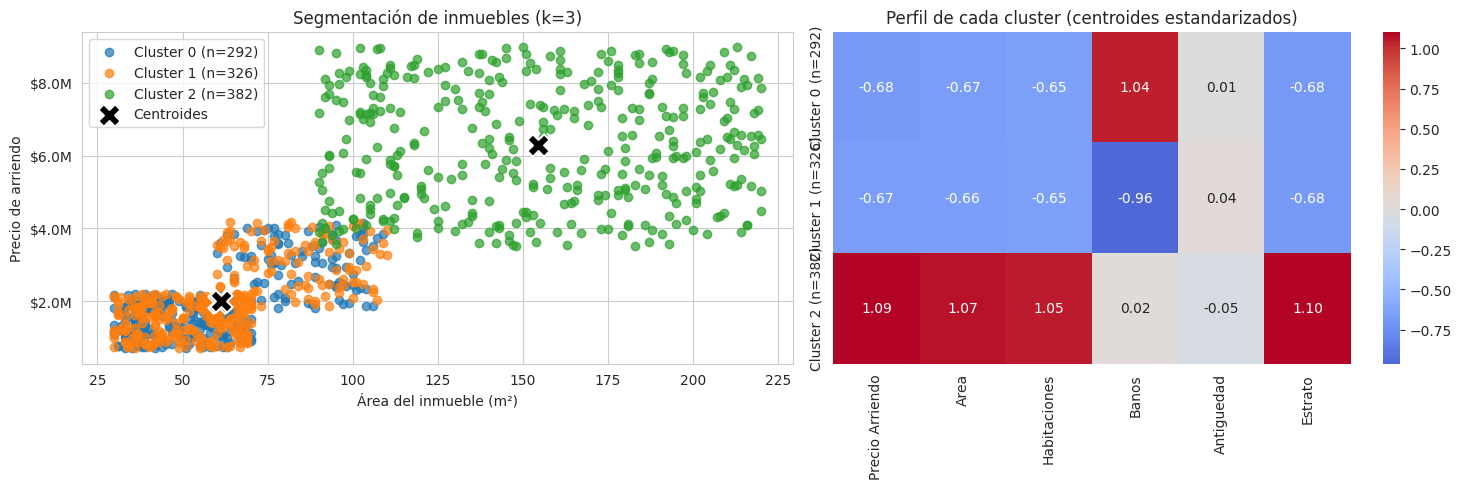

In [51]:
ejecutar_kmeans(3)

K-MEANS con k = 4   |   Inercia = 2113.12   |   Silueta = 0.318

Tamaño de cada cluster:
 cluster_k4
0    292
1    326
2    194
3    188

Centroides en escala estandarizada:
    Precio Arriendo  Area  Habitaciones  Banos  Antiguedad  Estrato
0            -0.68 -0.67         -0.65   1.04        0.01    -0.68
1            -0.67 -0.66         -0.65  -0.96        0.04    -0.68
2             1.08  1.07          1.02  -0.96       -0.05     1.10
3             1.11  1.07          1.09   1.04       -0.04     1.11

Centroides en escala original:
          Precio Arriendo    Area  Habitaciones  Banos  Antiguedad  Estrato
cluster                                                                   
0             1967061.15   60.68          1.83    2.0        8.48     2.98
1             2000101.25   61.25          1.83    1.0        8.56     2.99
2             6275222.41  154.76          3.96    1.0        8.34     5.52
3             6327014.21  154.35          4.06    2.0        8.37     5.54

Resume

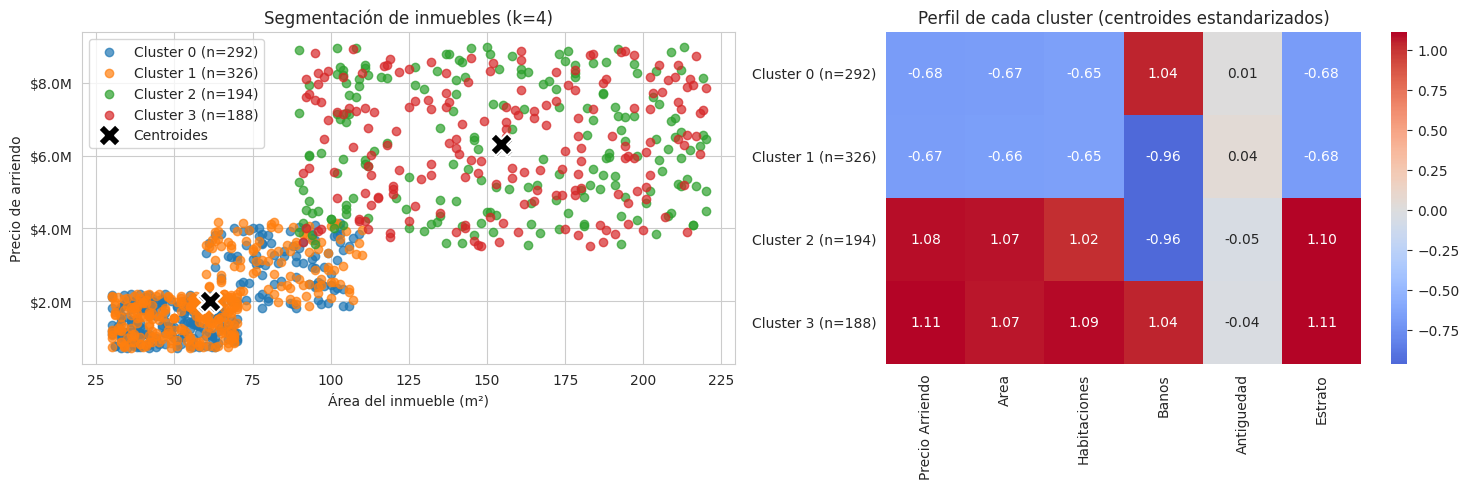

In [40]:
ejecutar_kmeans(4)

### Grafica comparativa entre la distribución de k=2,3,4

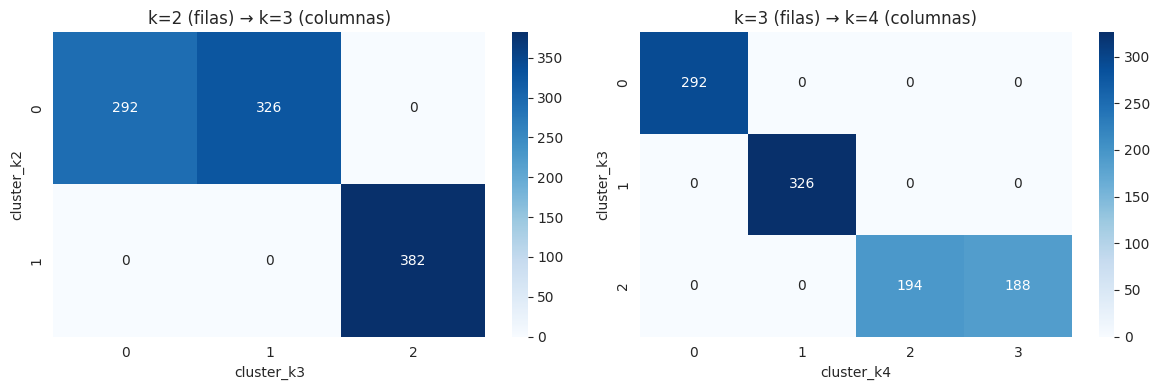

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(pd.crosstab(df_A["cluster_k2"], df_A["cluster_k3"]), annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_title("k=2 (filas) → k=3 (columnas)")
sns.heatmap(pd.crosstab(df_A["cluster_k3"], df_A["cluster_k4"]), annot=True, fmt="d", cmap="Blues", ax=ax[1])
ax[1].set_title("k=3 (filas) → k=4 (columnas)")
plt.tight_layout(); plt.show()

# **Parte B: Reducción de dimensiones con PCA**


### Preprocesamiento

Columnas del Excel (incluye ID): 9
Variables de entrada (sin ID):   8
Dimensiones tras el preprocesamiento (one-hot): (1000, 12)

Columnas resultantes: ['Precio Arriendo', 'Area', 'Habitaciones', 'Banos', 'Antiguedad', 'Estrato', 'Localidad_Chapinero', 'Localidad_Suba', 'Localidad_Usaquén', 'Tipo Inmueble_ApartaEstudio', 'Tipo Inmueble_Apto', 'Tipo Inmueble_Casa']


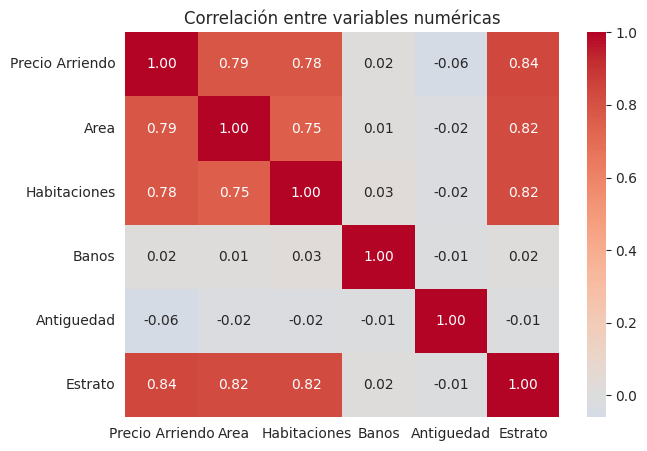

In [42]:
df_B = df_base.copy()
ids = df_B[col_id]                         # se conserva, NO se usa para distancias
X_B = df_B[vars_num + vars_cat]

preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", StandardScaler(), vars_num),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), vars_cat)
])
X_prep = preprocesamiento.fit_transform(X_B)
nombres = [n.split("__", 1)[1] for n in preprocesamiento.get_feature_names_out()]

print("Columnas del Excel (incluye ID):", df_base.shape[1])
print("Variables de entrada (sin ID):  ", X_B.shape[1])
print("Dimensiones tras el preprocesamiento (one-hot):", X_prep.shape)
print("\nColumnas resultantes:", nombres)

# Correlaciones: PCA aprovecha las variables correlacionadas
plt.figure(figsize=(7, 5))
sns.heatmap(df_B[vars_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas"); plt.show()

### Experimento A: K-Means sobre los datos preprocesados

In [43]:
K_ELEGIDO = 3

km = KMeans(n_clusters=K_ELEGIDO, random_state=42, n_init=10)
etiq_raw = km.fit_predict(X_prep)
grupos, orden = ordenar_por_precio(etiq_raw, df_B[col_precio])   # 0 = más económico
df_B["Grupo_KMeans"] = grupos
centros_prep = km.cluster_centers_[orden]

print(f"K-Means (k={K_ELEGIDO}) sobre {X_prep.shape[1]} dimensiones | silueta = {silhouette_score(X_prep, grupos):.3f}")
print(df_B["Grupo_KMeans"].value_counts().sort_index().to_string())

K-Means (k=3) sobre 12 dimensiones | silueta = 0.255
Grupo_KMeans
0    292
1    326
2    382


### PCA completo

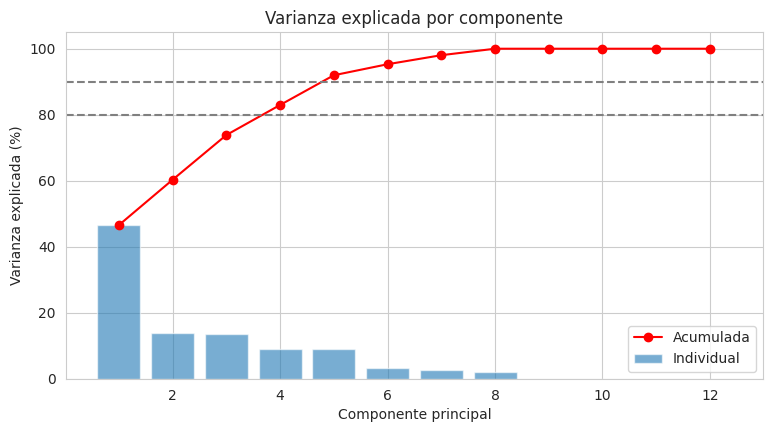

Componentes para 80%: 4 | para 90%: 5
Varianza individual de los 4 primeros (%): [46.54 13.75 13.55  9.1 ]


In [44]:
pca_full = PCA().fit(X_prep)
var_ind = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_ind)
n80 = int(np.argmax(var_acum >= 0.80)) + 1
n90 = int(np.argmax(var_acum >= 0.90)) + 1

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(1, len(var_ind) + 1), var_ind * 100, alpha=0.6, label="Individual")
ax.plot(range(1, len(var_ind) + 1), var_acum * 100, "o-", color="red", label="Acumulada")
ax.axhline(80, ls="--", color="gray"); ax.axhline(90, ls="--", color="gray")
ax.set_xlabel("Componente principal"); ax.set_ylabel("Varianza explicada (%)")
ax.set_title("Varianza explicada por componente"); ax.legend(); plt.show()

print(f"Componentes para 80%: {n80} | para 90%: {n90}")
print("Varianza individual de los 4 primeros (%):", (var_ind[:4] * 100).round(2))

### PCA con 2 componentes y gráfico PC1 vs PC2 coloreado por cluster

Dimensiones después del preprocesamiento: (1000, 12)
Dimensiones después de PCA: (1000, 2)
Varianza explicada por PC1: 46.54% | PC2: 13.75%
Varianza acumulada (PC1+PC2): 60.29%


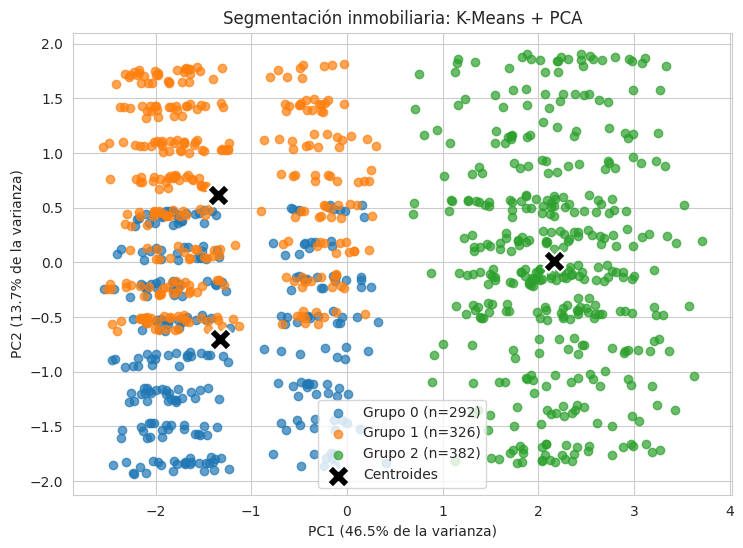

In [45]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_prep)

print("Dimensiones después del preprocesamiento:", X_prep.shape)
print("Dimensiones después de PCA:", X_pca.shape)
print("Varianza explicada por PC1: %.2f%% | PC2: %.2f%%" % tuple(pca.explained_variance_ratio_ * 100))
print("Varianza acumulada (PC1+PC2): %.2f%%" % (pca.explained_variance_ratio_.sum() * 100))

centros_pca = pca.transform(centros_prep)       # los centroides proyectados al plano

plt.figure(figsize=(8.5, 6))
for g in range(K_ELEGIDO):
    s = grupos == g
    plt.scatter(X_pca[s, 0], X_pca[s, 1], alpha=0.7, label=f"Grupo {g} (n={s.sum()})")
plt.scatter(centros_pca[:, 0], centros_pca[:, 1], marker="X", s=260, c="black",
            edgecolor="white", linewidth=1.5, label="Centroides", zorder=5)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% de la varianza)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% de la varianza)")
plt.title("Segmentación inmobiliaria: K-Means + PCA"); plt.legend(); plt.show()

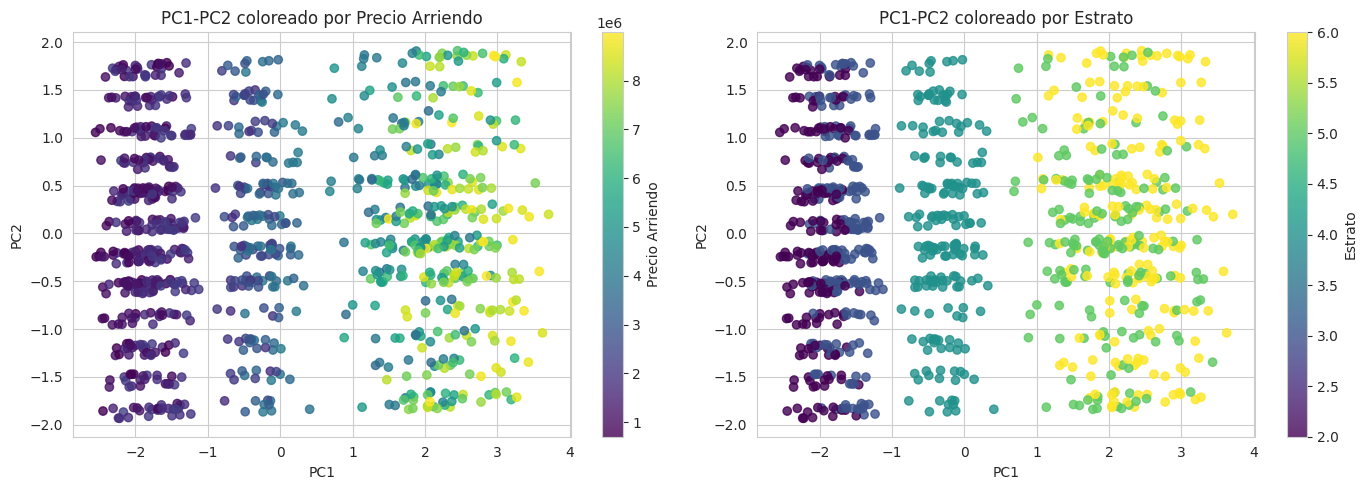

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, [col_precio, "Estrato"]):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=df_B[col], cmap="viridis", alpha=0.8)
    plt.colorbar(sc, ax=ax, label=col)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"PC1-PC2 coloreado por {col}")
plt.tight_layout(); plt.show()

### Perfil comercial de los grupos

Promedios por grupo:                Precio Arriendo    Area  Habitaciones  Banos  Antiguedad  \
Grupo_KMeans                                                             
0                  1967061.15   60.68          1.83   2.00        8.48   
1                  2000101.25   61.25          1.83   1.00        8.56   
2                  6300711.57  154.56          4.01   1.49        8.35   

              Estrato  
Grupo_KMeans           
0                2.98  
1                2.99  
2                5.53  


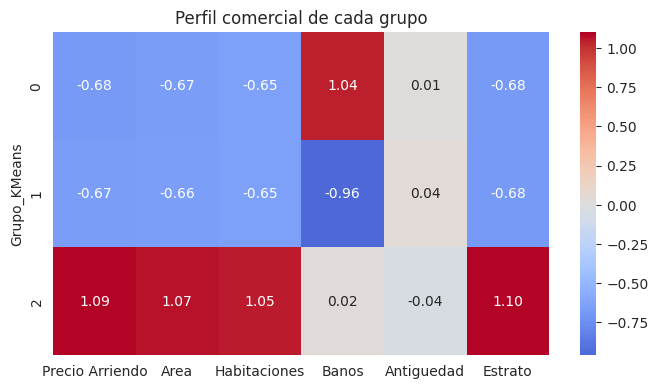

Localidad dentro de cada grupo (proporción):
Localidad     Chapinero  Suba  Usaquén
Grupo_KMeans                          
0                  0.36  0.35     0.29
1                  0.34  0.35     0.31
2                  0.30  0.31     0.38
Tipo Inmueble dentro de cada grupo (proporción):
Tipo Inmueble  ApartaEstudio  Apto  Casa
Grupo_KMeans                            
0                       0.29  0.35  0.36
1                       0.31  0.35  0.34
2                       0.38  0.31  0.30


In [47]:
medias = df_B.groupby("Grupo_KMeans")[vars_num].mean()
print("Promedios por grupo: ", medias.round(2))

z = (medias - df_B[vars_num].mean()) / df_B[vars_num].std()
plt.figure(figsize=(8, 0.9 * K_ELEGIDO + 1.5))

sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil comercial de cada grupo"); plt.show()

for cat in vars_cat:
  print(f"{cat} dentro de cada grupo (proporción):")
  print(pd.crosstab(df_B["Grupo_KMeans"], df_B[cat], normalize="index").round(2))